# Первинний аналіз Kickstarter для tbml

Автори проєкту: Бєлік Єгор і Глоба Максим, ПЗПІ-23-6.

Прогнозуємо досягнення цілі збору за параметрами, відомими до старту. Основне джерело — Kickstarter Projects (Mickaël Mouillé, CC BY-NC-SA 4.0). Короткі описи `blurb` приєднуємо за ID із фіксованого знімка Web Robots 2018-01-12. Їхню незмінність із моменту запуску не підтверджено; явна ліцензія повторного використання цього знімка не знайдена. Сирі тексти не публікуються в Git.

Мітка успіху не означає виконання проєкту. Назви кампаній не підміняють описи. `pledged`, `backers`, фінальний стан та похідні від фінансового результату заборонені як входи ML.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
if not (ROOT / 'ml').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from ml.features import load_campaigns, temporal_split, training_features
FIG = ROOT / 'reports/figures'
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (9, 4.5), 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
def show(name):
    plt.tight_layout(); plt.savefig(FIG / (name + '.png'), dpi=150, bbox_inches='tight')
    display(Image(filename=str(FIG / (name + '.png')))); plt.close()
raw = pd.read_csv(ROOT / 'data/raw/ks-projects-201801.csv', dtype={'ID': 'string'})
data, audit = load_campaigns(ROOT / 'data/raw/ks-projects-201801.csv', ROOT / 'data/raw/descriptions.csv')
source = json.loads((ROOT / 'reports/data/kickstarter-audit.json').read_text())
display(Markdown(f"**Розмір:** {len(raw):,} кампаній, {len(raw.columns)} колонок. Після відбору міток і перевірки чисел/дат: {len(data):,}. SHA-256 CSV: `{source['sha256']}`."))
display(raw.dtypes.astype(str).rename('тип').to_frame())

**Розмір:** 378,661 кампаній, 15 колонок. Після відбору міток і перевірки чисел/дат: 331,675. SHA-256 CSV: `4846177ce8cfacd06a6acf06cba663b9aa5f5f77e7d0debecf5bdc861a87e3cb`.

,тип
ID,string
name,object
category,object
main_category,object
currency,object
deadline,object
goal,float64
launched,object
pledged,float64
state,object


## Словник ознак і момент доступності

In [2]:
roles = {
 'ID': 'ID для зіставлення та дедуплікації; не прогнозна ознака',
 'name': 'Назва; не використовується як опис або ML-вхід',
 'category': 'Категорія на старті; категоріальна ознака',
 'main_category': 'Головна категорія на старті',
 'currency': 'Валюта цілі, відома на старті',
 'deadline': 'Планований дедлайн; для тривалості й очищення часових меж',
 'goal': 'Заявлена ціль у вихідній валюті; використовуємо log1p разом із валютою',
 'launched': 'Запуск: календарні ознаки та хронологічна валідація',
 'pledged': 'Зібрані кошти: ЗАБОРОНЕНО, відомі після старту',
 'state': 'Фінальна мітка, лише y: successful=1, failed=0',
 'backers': 'Кількість вкладників: ЗАБОРОНЕНО, відома після старту',
 'country': 'Країна автора, категоріальна ознака',
 'usd pledged': 'Зібрані кошти: ЗАБОРОНЕНО',
 'usd_pledged_real': 'Зібрані кошти: ЗАБОРОНЕНО',
 'usd_goal_real': 'Не використовуємо: момент визначення курсу не підтверджений',
 'blurb': 'Окреме джерело: справжній короткий опис, походження до запуску не доведено'}
display(pd.DataFrame([{'ознака': key, 'значення та політика': value} for key,value in roles.items()]))
catalog = {'categories': raw[['category','main_category']].dropna().drop_duplicates().sort_values(['main_category','category']).to_dict('records'),
           'currencies': sorted(raw.currency.dropna().unique().tolist()),
           'countries': sorted([v for v in raw.country.dropna().unique() if len(v)==2 and v.isalpha()])}
(ROOT / 'reports/data/catalog.json').write_text(json.dumps(catalog, ensure_ascii=False, indent=2))

,ознака,значення та політика
0,ID,ID для зіставлення та дедуплікації; не прогноз...
1,name,Назва; не використовується як опис або ML-вхід
2,category,Категорія на старті; категоріальна ознака
3,main_category,Головна категорія на старті
4,currency,"Валюта цілі, відома на старті"
5,deadline,Планований дедлайн; для тривалості й очищення ...
6,goal,Заявлена ціль у вихідній валюті; використовуєм...
7,launched,Запуск: календарні ознаки та хронологічна валі...
8,pledged,"Зібрані кошти: ЗАБОРОНЕНО, відомі після старту"
9,state,"Фінальна мітка, лише y: successful=1, failed=0"


13591

## Рисунок 1 Стани кампаній і баланс цільових класів

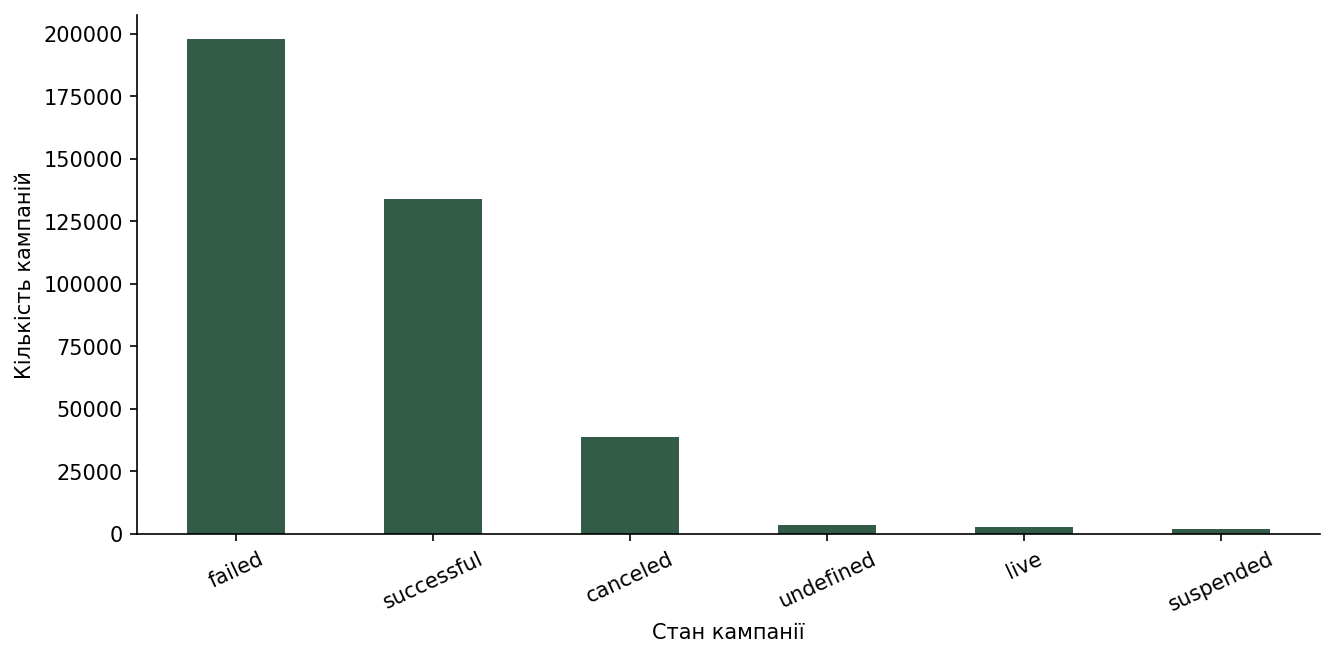

Висновок: частка успіху серед successful/failed — **40.39%**. Класи незбалансовані, тому accuracy недостатньо; оцінюємо F1, ROC-AUC, PR-AUC і калібрування. Незавершені й скасовані кампанії не прирівнюємо автоматично до failed.

In [3]:
counts = raw.state.value_counts()
counts.plot.bar(color='#335c48'); plt.ylabel('Кількість кампаній'); plt.xlabel('Стан кампанії'); plt.xticks(rotation=25)
show('01-class-balance')
p = data.state.eq('successful').mean()
display(Markdown(f'Висновок: частка успіху серед successful/failed — **{p:.2%}**. Класи незбалансовані, тому accuracy недостатньо; оцінюємо F1, ROC-AUC, PR-AUC і калібрування. Незавершені й скасовані кампанії не прирівнюємо автоматично до failed.'))

## Рисунок 2 Розподіл цілі збору в доларах США

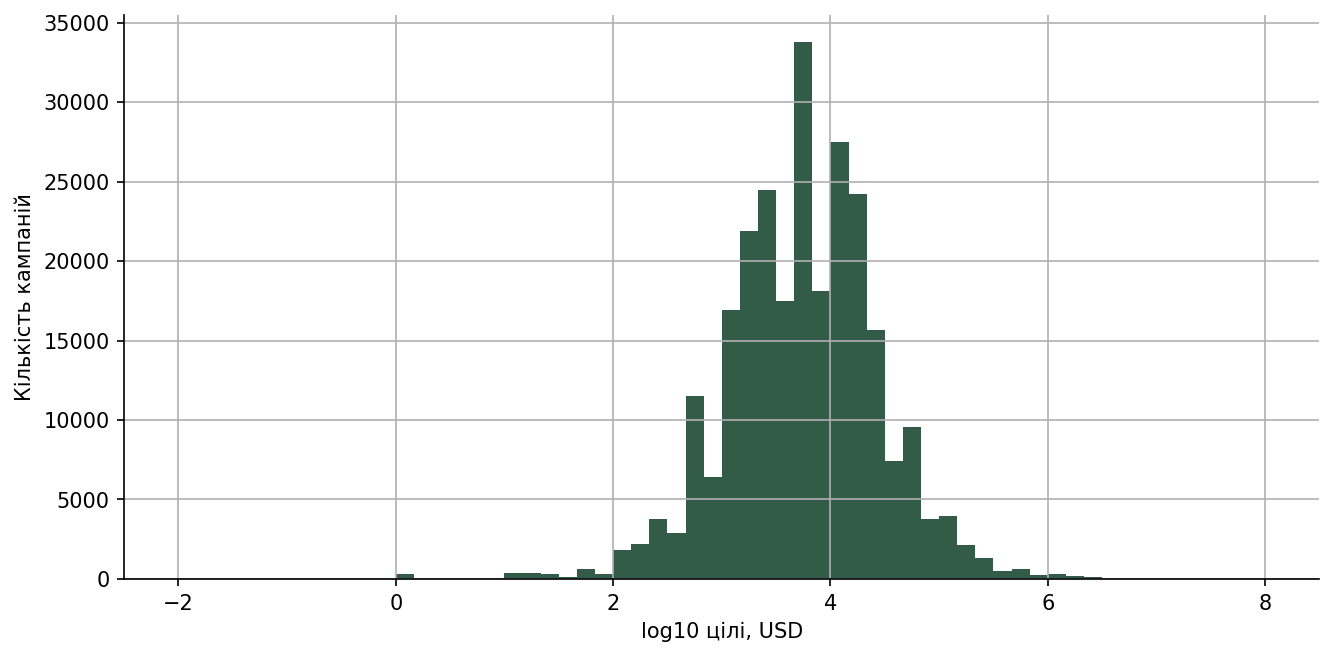

Висновок: медіана цілі в USD — **5,000**, 99-й процентиль — **260,000**. Цілі мають довгий хвіст; використовуємо log1p. Для цього графіка обрано лише USD, щоб не змішувати різні валюти.

In [4]:
usd = data.loc[data.currency.eq('USD'), 'goal']
np.log10(usd).hist(bins=60, color='#335c48'); plt.xlabel('log10 цілі, USD'); plt.ylabel('Кількість кампаній')
show('02-goal-distribution')
display(Markdown(f'Висновок: медіана цілі в USD — **{usd.median():,.0f}**, 99-й процентиль — **{usd.quantile(.99):,.0f}**. Цілі мають довгий хвіст; використовуємо log1p. Для цього графіка обрано лише USD, щоб не змішувати різні валюти.'))

## Рисунок 3 Запланована тривалість збору

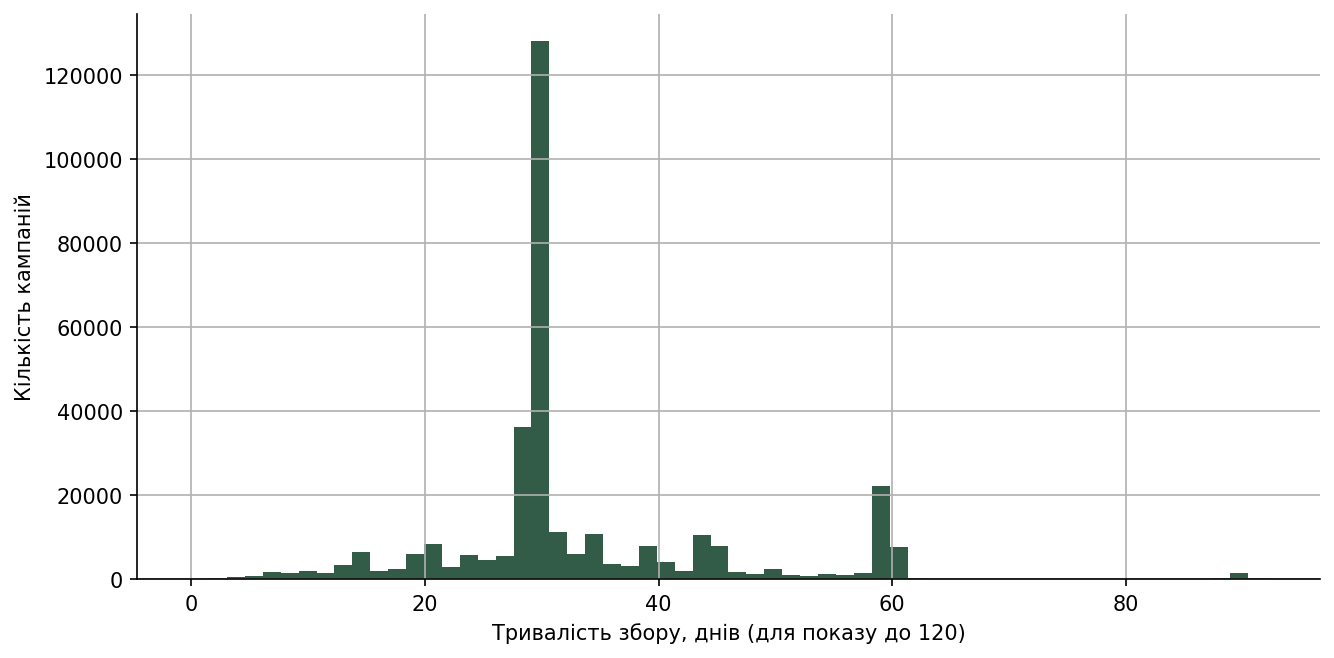

Висновок: медіана тривалості — **29.7 днів**, понад 120 днів мають **0** кампаній. Наддовгі та помилкові дати потребують окремого аналізу; позитивні значення автоматично не обрізаємо за тестовими даними.

In [5]:
duration = (data.deadline-data.launched).dt.total_seconds()/86400
duration[duration.le(120)].hist(bins=60, color='#335c48'); plt.xlabel('Тривалість збору, днів (для показу до 120)'); plt.ylabel('Кількість кампаній')
show('03-duration')
display(Markdown(f'Висновок: медіана тривалості — **{duration.median():.1f} днів**, понад 120 днів мають **{duration.gt(120).sum()}** кампаній. Наддовгі та помилкові дати потребують окремого аналізу; позитивні значення автоматично не обрізаємо за тестовими даними.'))

## Рисунок 4 Пропуски в початковому наборі

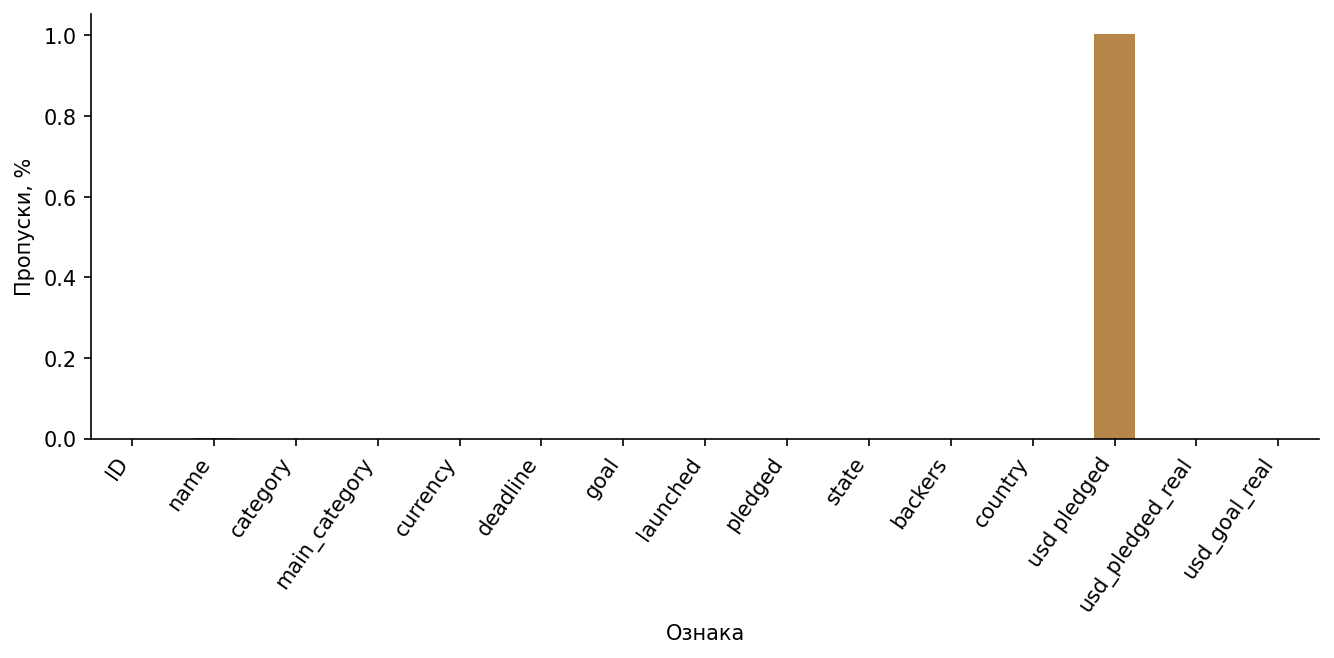

Висновок: у name пропущено **4**, у usd pledged — **3797** значень. Ці поля не є входами поточних моделей; для допустимих числових входів imputer навчається лише на train.

In [6]:
missing = raw.isna().mean().mul(100)
missing.plot.bar(color='#b68648'); plt.ylabel('Пропуски, %'); plt.xlabel('Ознака'); plt.xticks(rotation=55, ha='right')
show('04-missing')
display(Markdown(f'Висновок: у name пропущено **{raw.name.isna().sum()}**, у usd pledged — **{raw["usd pledged"].isna().sum()}** значень. Ці поля не є входами поточних моделей; для допустимих числових входів imputer навчається лише на train.'))

## Рисунок 5 Залежності між допустимими ознаками та міткою

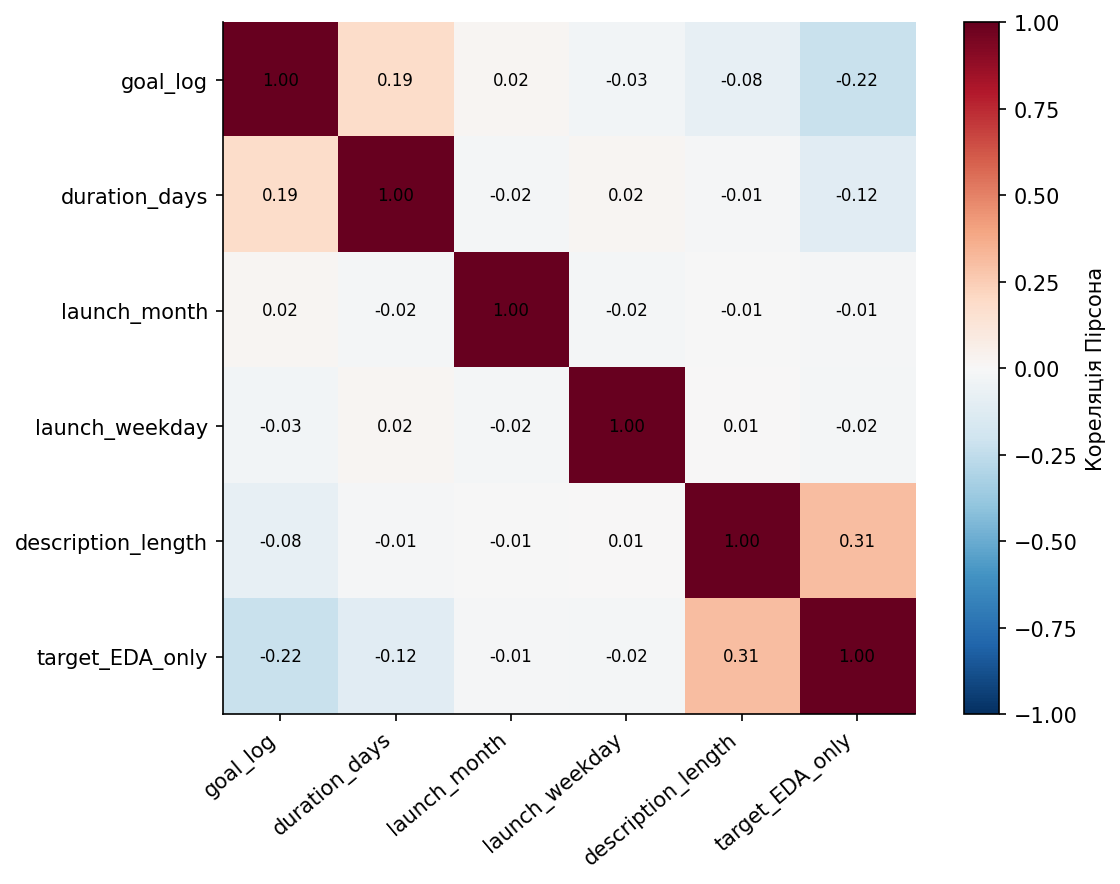

Висновок: кореляції описують лінійні залежності й не доводять причинності. Стовпець target додано лише для EDA; він не передається до ML-конвеєра. Відсутність сильної кореляції не означає відсутності нелінійного сигналу.

In [7]:
X = training_features(data)
corr_data = X[['goal_log','duration_days','launch_month','launch_weekday']].copy()
corr_data['description_length'] = data.description.str.len()
corr_data['target_EDA_only'] = data.state.eq('successful').astype(int)
corr = corr_data.corr()
fig, ax = plt.subplots(figsize=(8,6)); image=ax.imshow(corr, vmin=-1,vmax=1,cmap='RdBu_r')
ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha='right'); ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
 for j in range(len(corr)): ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=8)
fig.colorbar(image,ax=ax,label='Кореляція Пірсона'); show('05-correlations')
display(Markdown('Висновок: кореляції описують лінійні залежності й не доводять причинності. Стовпець target додано лише для EDA; він не передається до ML-конвеєра. Відсутність сильної кореляції не означає відсутності нелінійного сигналу.'))

## Рисунок 6 Викиди цілі збору

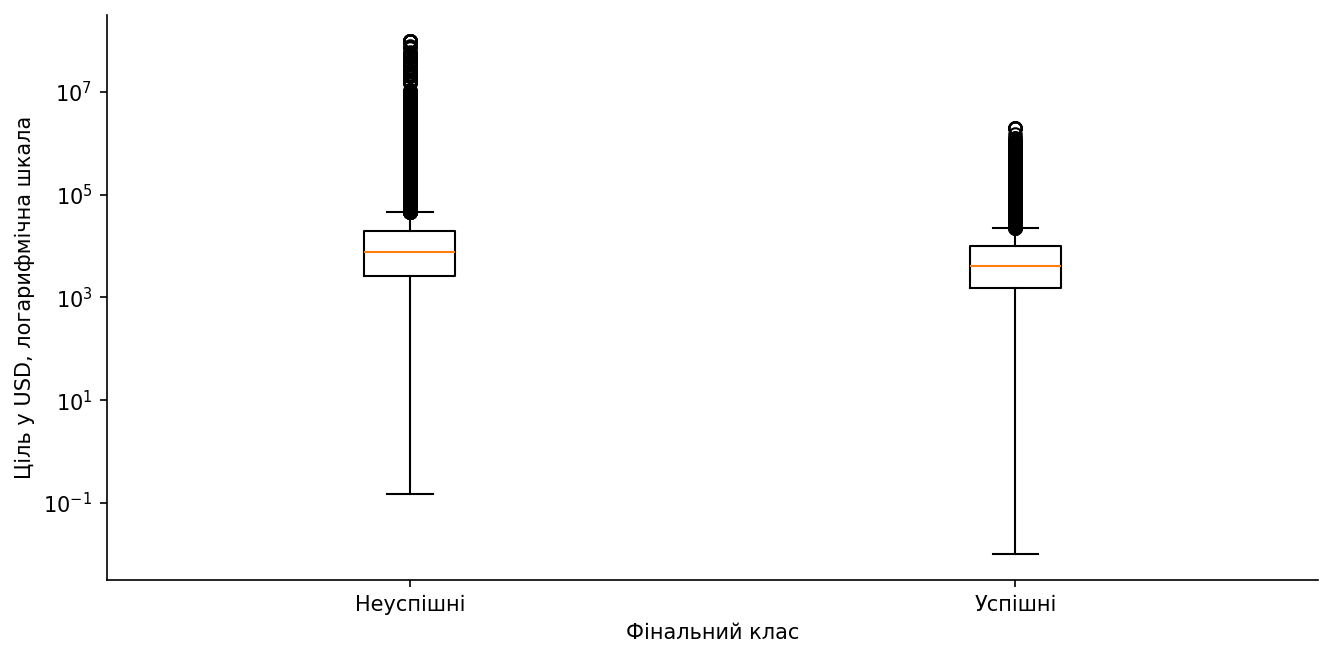

Висновок: за верхньою межею 1.5 IQR в USD — **29,616** кампаній. Частина великих цілей реальна; не видаляємо їх лише через відхилення від медіани. Використовуємо логарифмування й перевіряємо помилки чисел/дат.

In [8]:
plt.boxplot([usd[data.loc[usd.index,'state'].eq(s)] for s in ['failed','successful']], tick_labels=['Неуспішні','Успішні'], showfliers=True)
plt.yscale('log'); plt.ylabel('Ціль у USD, логарифмічна шкала'); plt.xlabel('Фінальний клас')
show('06-outliers')
q1,q3=usd.quantile([.25,.75]); outliers=(usd.gt(q3+1.5*(q3-q1))).sum()
display(Markdown(f'Висновок: за верхньою межею 1.5 IQR в USD — **{outliers:,}** кампаній. Частина великих цілей реальна; не видаляємо їх лише через відхилення від медіани. Використовуємо логарифмування й перевіряємо помилки чисел/дат.'))

## Рисунок 7 Зміна потоку кампаній у часі

/tmp/ipykernel_8885/4015295158.py:1: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  timeline=data.groupby(data.launched.dt.to_period('M').astype(str)).agg(n=('ID','size'),success=('state',lambda v:v.eq('successful').mean()))


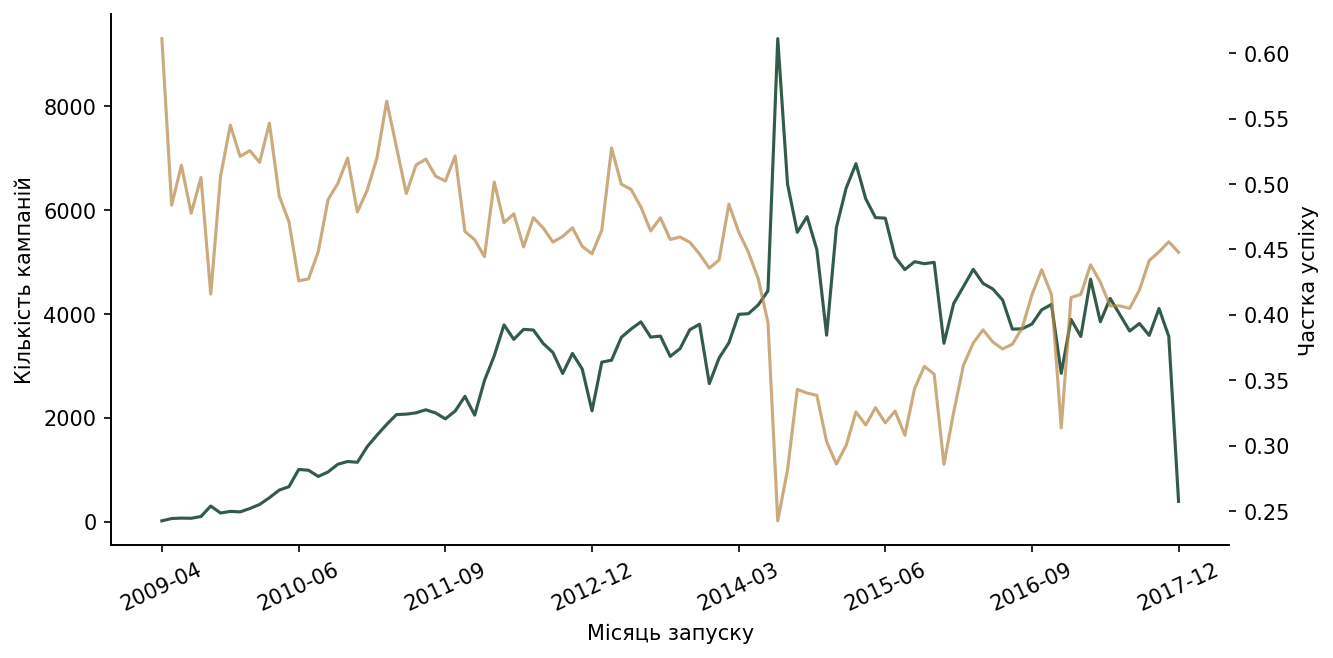

Висновок: дані охоплюють запуски від **2009-04-21** до **2017-12-29**. Розподіл змінюється в часі, тому основний split — хронологічний; результат навчальної кампанії має бути відомий до початку наступного періоду.

In [9]:
timeline=data.groupby(data.launched.dt.to_period('M').astype(str)).agg(n=('ID','size'),success=('state',lambda v:v.eq('successful').mean()))
fig,ax=plt.subplots(); ax.plot(range(len(timeline)),timeline.n,color='#335c48',label='Кампанії')
indices=np.linspace(0,len(timeline)-1,8).astype(int); ax.set_xticks(indices,timeline.index[indices],rotation=25)
ax.set_xlabel('Місяць запуску'); ax.set_ylabel('Кількість кампаній')
ax2=ax.twinx(); ax2.plot(range(len(timeline)),timeline.success,color='#b68648',alpha=.7); ax2.set_ylabel('Частка успіху'); show('07-timeline')
display(Markdown(f'Висновок: дані охоплюють запуски від **{data.launched.min().date()}** до **{data.launched.max().date()}**. Розподіл змінюється в часі, тому основний split — хронологічний; результат навчальної кампанії має бути відомий до початку наступного періоду.'))

## Рисунок 8 Покриття справжніми короткими описами

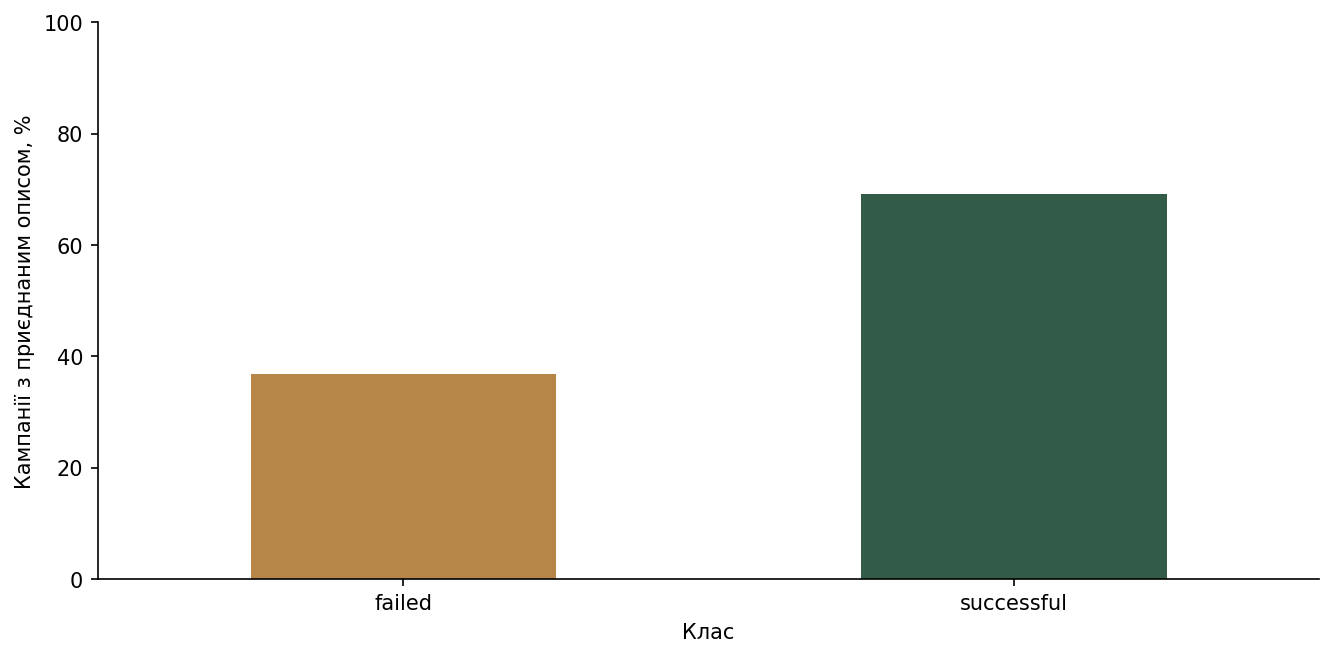

Висновок: приєднано **165,434** непорожніх описів за ID. Покриття може залежати від класу й року; усі три методи порівнюємо на однаковій підмножині з текстом. Походження текстів до запуску не доведено, тому результати є ретроспективними.

In [10]:
coverage=data.assign(has_text=data.description.str.strip().ne('')).groupby('state').has_text.mean().mul(100)
coverage.plot.bar(color=['#b68648','#335c48']); plt.ylabel('Кампанії з приєднаним описом, %'); plt.xlabel('Клас'); plt.xticks(rotation=0); plt.ylim(0,100)
show('08-description-coverage')
display(Markdown(f'Висновок: приєднано **{data.description.str.strip().ne("").sum():,}** непорожніх описів за ID. Покриття може залежати від класу й року; усі три методи порівнюємо на однаковій підмножині з текстом. Походження текстів до запуску не доведено, тому результати є ретроспективними.'))

## Схема валідації та підсумкові рішення

In [11]:
cohort=data[data.description.str.strip().ne('')].reset_index(drop=True)
parts,split=temporal_split(cohort)
display(pd.DataFrame([{'частина':k,'рядків':len(v),'від':str(v.launched.min().date()),'до':str(v.launched.max().date()),'успіх':v.state.eq('successful').mean()} for k,v in parts.items()]))
display(Markdown(f'На часових межах вилучено **{split["purged_boundary_rows"]:,}** кампаній, результат яких ще не був би відомий до наступного періоду. Усі перетворення fit лише на train. Поріг класифікації та вибір моделі визначаються validation, фінальні метрики — на відкладеному test.'))
summary={**audit,'split':split,'source_sha256':source['sha256'],'missing':raw.isna().sum().to_dict(),'duplicate_ids':int(raw.ID.duplicated().sum())}
(ROOT/'reports/data/eda-summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2))
display(Markdown('Підсумок: не змішуємо валюти без їх коду; трансформуємо довгий хвіст цілей; не використовуємо фінансовий результат як ознаки; враховуємо часові межі доступності міток; окремо звітуємо про неповне текстове покриття, невідомі умови повторного використання знімка та можливе редагування описів.'))

,частина,рядків,від,до,успіх
0,train,113038,2009-04-24,2015-09-10,0.595251
1,validation,23069,2015-09-16,2016-09-06,0.445620
2,test,24845,2016-09-13,2017-12-29,0.536446


На часових межах вилучено **4,482** кампаній, результат яких ще не був би відомий до наступного періоду. Усі перетворення fit лише на train. Поріг класифікації та вибір моделі визначаються validation, фінальні метрики — на відкладеному test.

Підсумок: не змішуємо валюти без їх коду; трансформуємо довгий хвіст цілей; не використовуємо фінансовий результат як ознаки; враховуємо часові межі доступності міток; окремо звітуємо про неповне текстове покриття, невідомі умови повторного використання знімка та можливе редагування описів.